Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 32)                  │           4,864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector (RepeatVector)         │ (None, 10, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 10, 32)              │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed (TimeDistributed)   │ (None, 10, 5)               │             165 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 13,349 (52.14 KB)

 Trainable params: 13,349 (52.14 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 9s 43ms/step - loss: 0.0654 - mae: 0.2000 - val_loss: 0.0284 - val_mae: 0.1322
Epoch 2/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0229 - mae: 0.1177 - val_loss: 0.0179 - val_mae: 0.1046
Epoch 3/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0176 - mae: 0.1035 - val_loss: 0.0167 - val_mae: 0.1013
Epoch 4/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0170 - mae: 0.1018 - val_loss: 0.0164 - val_mae: 0.1003
Epoch 5/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0167 - mae: 0.1009 - val_loss: 0.0162 - val_mae: 0.0995
Epoch 6/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 0.0165 - mae: 0.1001 - val_loss: 0.0159 - val_mae: 0.0987
Epoch 7/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.0163 - mae: 0.0994 - val_loss: 0.0157 - val_mae: 0.0980
Epoch 8/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0161 - mae: 0.0988 - val_loss: 0.0156 - val_mae: 0.0975
Epoch 9/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.016

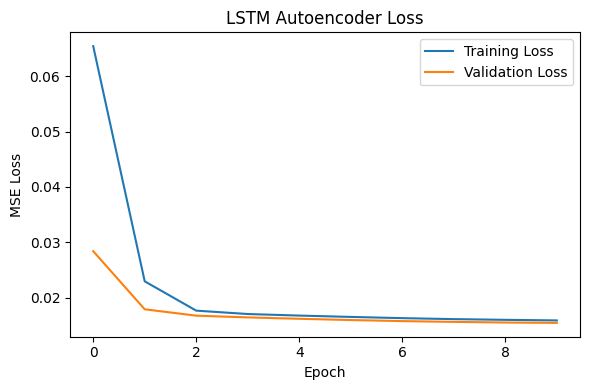

In [1]:
# 3C - Anomaly Detection in Energy Consumption using LSTM Autoencoder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report
from tensorflow import keras


# 1. LOAD DATASET
data = pd.read_csv("energy consumption.csv")

# Fill missing values
data = data.ffill()

# Separate features and labels
features = data.drop(["Timestamp", "Anomaly_Label"], axis=1).values
labels = data["Anomaly_Label"].values      # 0 = Normal, 1 = Anomaly

# Scale features between 0 and 1
scaler = MinMaxScaler()
features = scaler.fit_transform(features)


# 2. CREATE TIME WINDOWS OF 10 ROWS
x, y = [], []

for i in range(len(features) - 10):
    x.append(features[i:i + 10])
    y.append(labels[i + 9])

x = np.array(x)
y = np.array(y)


# 3. USE ONLY NORMAL DATA FOR TRAINING
x_normal = x[y == 0]


# 4. CREATE LSTM AUTOENCODER
n = x.shape[2]

model = keras.Sequential([
    # Encoder
    keras.layers.Input(shape=(10, n)),
    keras.layers.LSTM(32),

    # Repeat the encoded vector for each time step
    keras.layers.RepeatVector(10),

    # Decoder
    keras.layers.LSTM(32, return_sequences=True),
    keras.layers.TimeDistributed(
        keras.layers.Dense(n)
    )
])


# 5. COMPILE MODEL
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()


# 6. TRAIN THE MODEL
# Input = Output because this is an autoencoder
history = model.fit(
    x_normal,
    x_normal,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)


# 7. RECONSTRUCT ALL SEQUENCES
reconstructed = model.predict(x, verbose=0)


# 8. CALCULATE RECONSTRUCTION ERROR
error = np.mean(
    np.square(x - reconstructed),
    axis=(1, 2)
)


# 9. SET ANOMALY THRESHOLD
# 95th percentile of normal reconstruction errors
threshold = np.percentile(error[y == 0], 95)

print("\nThreshold:", threshold)


# 10. PREDICT ANOMALIES
# High reconstruction error = anomaly
y_pred = (error > threshold).astype(int)


# 11. DISPLAY CLASSIFICATION RESULTS
print("\nClassification Report:")
print(classification_report(y, y_pred))


# 12. PLOT TRAINING AND VALIDATION LOSS
plt.figure(figsize=(6, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Autoencoder Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()

plt.tight_layout()
plt.show()